# Mcculloch_Pitts Neuron

In [1]:
def mcculloch_pitts(inputs, weights, threshold):
  weighted_sum = sum([inputs[i] * weights[i] for i in range(len(inputs))])
  if weighted_sum >= threshold:
    return 1
  else:
    return 0


In [2]:
# Example input
inputs = [1, 0, 1]
weights = [1, -1, 0]
threshold = 1

In [3]:
# Compute output
output = mcculloch_pitts(inputs, weights, threshold)
print(output)

1


## Verify Logic Gates

In [15]:
import numpy as np
from itertools import product
import matplotlib.pyplot as plt

In [6]:
list(product([0, 1], repeat=2))

[(0, 0), (0, 1), (1, 0), (1, 1)]

In [7]:
def mcp_neuron(inputs, weights, threshold):
  x = np.asarray(inputs)
  w = np.asarray(weights)
  weighted_sum = np.dot(x, w)
  if weighted_sum >= threshold:
    return 1
  else:
    return 0

In [8]:
def show_truth_table(weights, threshold, gate_name="Neuron"):
  print(f"{gate_name}")
  print("x1 x2 | y")
  print("----------")
  for x1, x2 in product([0, 1], repeat=2):
    y = mcp_neuron([x1, x2], weights, threshold)
    print(f"{x1}  {x2}  | {y}")


In [9]:
# AND Gate
show_truth_table([1, 1], 2, "AND Gate")

AND Gate
x1 x2 | y
----------
0  0  | 0
0  1  | 0
1  0  | 0
1  1  | 1


In [10]:
# OR Gate
show_truth_table([1, 1], 1, "OR Gate")

OR Gate
x1 x2 | y
----------
0  0  | 0
0  1  | 1
1  0  | 1
1  1  | 1


## X-OR Gate: Home work

#Decision Boundaries

In [22]:
def plot_gate_boundary(weights, threshold, title):
  w1, w2 = weights

  points = np.array([(0,0), (0,1), (1,0), (1,1)])
  outputs = np.array([mcp_neuron(point, weights, threshold) for point in points])

  plt.figure(figsize=(6,5))

  for p, y in zip(points, outputs):
    marker = "o" if y==1 else "x"
    plt.scatter(p[0], p[1], marker=marker, s=100)
    plt.text(p[0] +0.03, p[1] + 0.03, f"y={y}", fontsize=12)

  x1_vals = np.linspace(-0.2, 1.2, 100)
  if w2 !=0:
    x2_vals = (threshold - w1 * x1_vals) / w2
    plt.plot(x1_vals, x2_vals)

  plt.xlim(-0.2, 1.2)
  plt.ylim(-0.2, 1.2)
  plt.xlabel("x1")
  plt.ylabel("x2")
  plt.title(title)




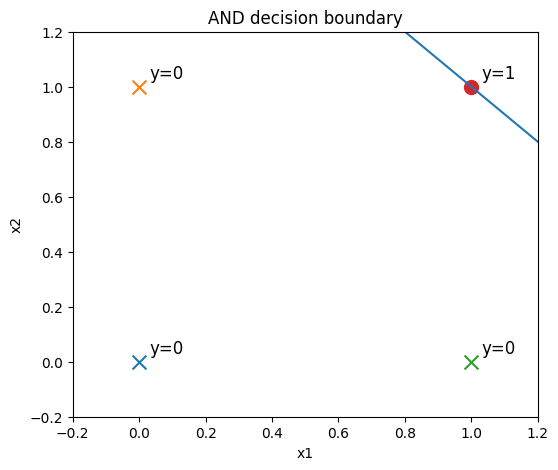

In [23]:
plot_gate_boundary([1,1], 2, "AND decision boundary")

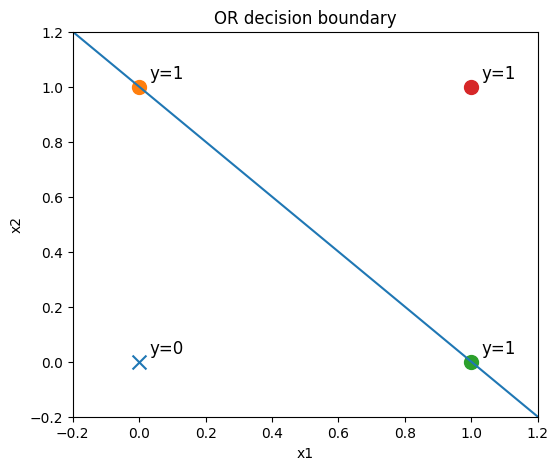

In [24]:
plot_gate_boundary([1,1], 1, "OR decision boundary")